<a href="https://colab.research.google.com/github/202451125/NutriScore/blob/main/notebooks/NutriScore_Model_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🥗 NutriScore: AI-Based Food Recognition & Nutritional Analysis

> **Motto:** *"Know What You Eat — Empowering Healthy Choices with Computer Vision"*

---

### 📌 Project Objective
NutriScore is an end-to-end intelligent dietary assistant that identifies food items from real-world photographs using Deep Learning (Transfer Learning) and instantly provides:
1. **Food Category Recognition & Confidence Score**
2. **Nutritional Breakdown:** Calories, Protein, Carbohydrates, and Fats
3. **Official European Nutri-Score Grade (A to E):**
   - 🟩 **A (Dark Green):** Highest nutritional quality
   - 🟢 **B (Light Green):** Good nutritional quality
   - 🟡 **C (Yellow):** Fair / Moderate nutritional quality
   - 🟧 **D (Orange):** Poor nutritional quality (Consume in moderation)
   - 🟥 **E (Dark Red):** Lowest nutritional quality (High fat/sugar/sodium)
4. **Actionable Dietary Recommendations**

---

### Pipeline Overview
`Image Input` ➔ `Data Augmentation` ➔ `MobileNetV2 Feature Extractor` ➔ `Dense Softmax Classifier` ➔ `Nutrition & Nutri-Score Mapping` ➔ `Health Guidance`

In [1]:
import tensorflow as tf
print("Tensorflow", tf.__version__)

if tf.config.list_physical_devices('GPU'):
    print("GPU is available")
else:
    print("GPU is not available")


Tensorflow 2.21.0
GPU is available


## 1. Dataset Acquisition
We are downloading the benchmark food image dataset. The images are pre-organized into `train/` and `test/` splits across categories.

In [3]:
import urllib.request
import zipfile
import os

dataset_url = "https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip"
zip_filename = "10_food_classes_all_data.zip"

print("Downloading dataset from Google Cloud Storage....")
urllib.request.urlretrieve(dataset_url, zip_filename)

print("Unzipping dataset....")
with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall()
print("✅ Dataset downloaded and extracted successfully!")

Unzipping dataset....
✅ Dataset downloaded and extracted successfully!


## 2. Exploratory Data Analysis (EDA)

Before building our model, we explore the dataset:
- Verify folder structure and class names
- Check class distribution across training and testing sets
- Inspect image resolutions and sample visual data

In [5]:
import os
import pathlib

main_dir = "10_food_classes_all_data"
train_dir = os.path.join(main_dir, "train")
test_dir = os.path.join(main_dir, "test")

class_names = sorted(os.listdir(train_dir))
num_classes = len(class_names)

print(f"Total class found: {num_classes}")
print("Class_labels:", class_names)
print("-"*50)

Total class found: 10
Class_labels: ['chicken_curry', 'chicken_wings', 'fried_rice', 'grilled_salmon', 'hamburger', 'ice_cream', 'pizza', 'ramen', 'steak', 'sushi']
--------------------------------------------------


In [6]:
print(f"{'Class Name':<25} {'Train Images':<15} {'Test Images':<15}")
print("-" * 55)
total_train = 0
total_test = 0
for class_name in class_names:
    train_path = os.path.join(train_dir, class_name)
    test_path = os.path.join(test_dir, class_name)

    n_train = len(os.listdir(train_path))
    n_test = len(os.listdir(test_path))

    total_train += n_train
    total_test += n_test

    print(f"{class_name:<25} {n_train:<15} {n_test:<15}")
print("-" * 55)
print(f"{'Total':<25} {total_train:<15} {total_test:<15}")

Class Name                Train Images    Test Images    
-------------------------------------------------------
chicken_curry             750             250            
chicken_wings             750             250            
fried_rice                750             250            
grilled_salmon            750             250            
hamburger                 750             250            
ice_cream                 750             250            
pizza                     750             250            
ramen                     750             250            
steak                     750             250            
sushi                     750             250            
-------------------------------------------------------
Total                     7500            2500           


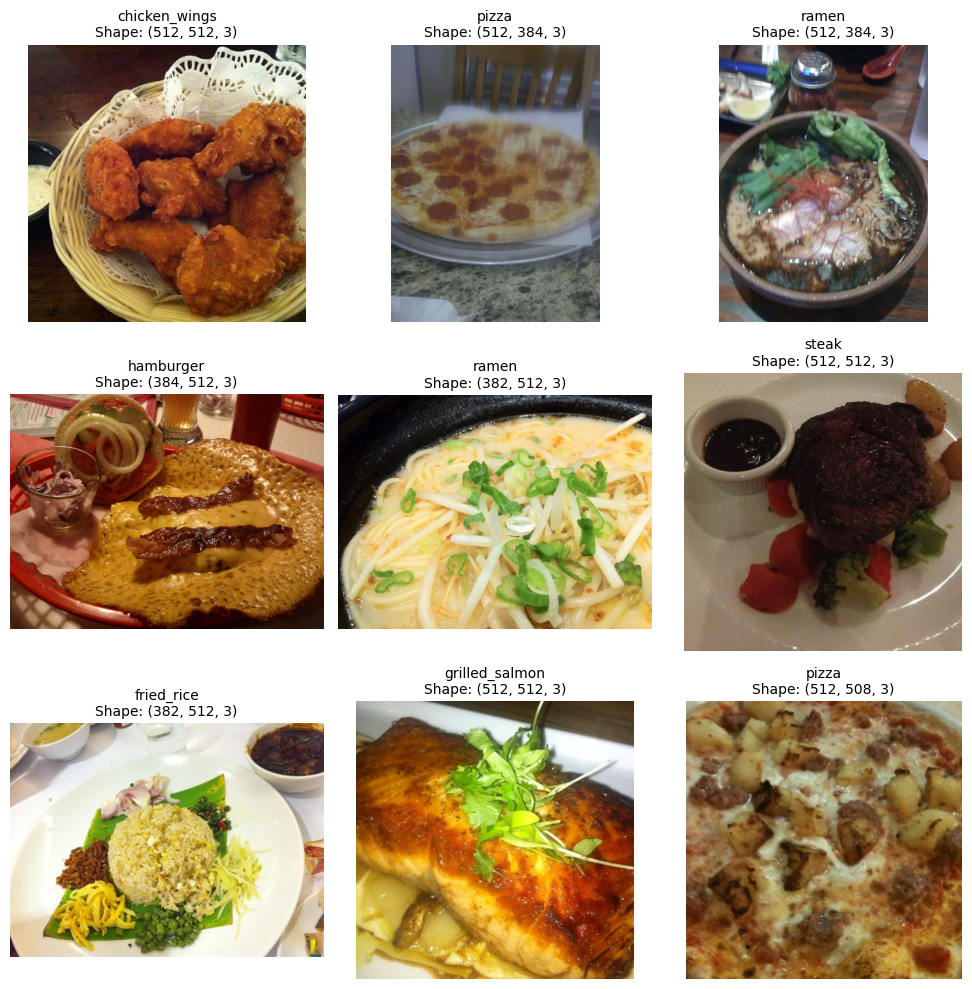

In [7]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

# Function to view a random image from a random class
plt.figure(figsize=(10, 10))

for i in range(9):
    # Pick a random class and random image
    random_class = random.choice(class_names)
    random_dir = os.path.join(train_dir, random_class)
    random_img_name = random.choice(os.listdir(random_dir))
    random_img_path = os.path.join(random_dir, random_img_name)

    # Read image
    img = mpimg.imread(random_img_path)

    # Plot
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(f"{random_class}\nShape: {img.shape}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Data Loading and Preprocessing

We use `image_dataset_from_directory` to load images from disk into efficient `tf.data.Dataset` pipelines.
- Target image size: 224x224 (standard for MobileNetV2)
- Batch size: 32
- Label mode: categorical (one-hot encoded for multi-class classification)

In [8]:
# Define parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load training data
print("Loading Training Dataset:")
train_data = tf.keras.utils.image_dataset_from_directory(
    directory=train_dir,
    image_size=IMG_SIZE,
    label_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Load test data
print("\nLoading Test / Validation Dataset:")
test_data = tf.keras.utils.image_dataset_from_directory(
    directory=test_dir,
    image_size=IMG_SIZE,
    label_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

Loading Training Dataset:
Found 7500 files belonging to 10 classes.

Loading Test / Validation Dataset:
Found 2500 files belonging to 10 classes.


## 5. Model Architecture: Transfer Learning with MobileNetV2

We construct a transfer learning model using MobileNetV2 as the feature extractor backbone:
1. Input Layer: Shape (224, 224, 3)
2. Data Augmentation: Integrated directly into the model graph
3. MobileNetV2 Preprocessing: Scales pixel values to [-1, 1]
4. Pretrained MobileNetV2 Base: Frozen weights (`trainable = False`)
5. GlobalAveragePooling2D: Condenses spatial feature maps to a 1D vector (1280 features)
6. Dropout (0.3): Regularization to mitigate overfitting
7. Dense Classification Head: 10 units with Softmax activation

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 1. Define Data Augmentation Block directly
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# 2. Define Input Layer
inputs = layers.Input(shape=(224, 224, 3), name="input_image")

# 3. Apply Data Augmentation
x = data_augmentation(inputs)

# 4. Apply MobileNetV2 Preprocessing (scales [0, 255] to [-1, 1])
x = preprocess_input(x)

# 5. Load Pretrained MobileNetV2 Base (without the ImageNet 1000-class head)
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze base model weights so they are not altered during initial training
base_model.trainable = False

# Pass data through frozen base
x = base_model(x, training=False)

# 6. Global Average Pooling (condenses 7x7x1280 feature maps into a 1280 vector)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)

# 7. Dropout (randomly drops 30% of connections to prevent overfitting)
x = layers.Dropout(0.3, name="dropout_layer")(x)

# 8. Final Dense Layer with Softmax (outputs probabilities for our 10 classes)
outputs = layers.Dense(10, activation="softmax", name="output_layer")(x)

# 9. Create Complete Model
model = models.Model(inputs=inputs, outputs=outputs, name="NutriScore_MobileNetV2")

# 10. Compile Model
model.compile(
    loss="categorical_crossentropy",
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

# Print architecture summary
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "NutriScore_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Model Training & Callbacks

We train the model using:
- **EarlyStopping**: Halts training if `val_loss` fails to improve for 3 consecutive epochs
- **ModelCheckpoint**: Automatically saves the best model weights to `best_nutriscore_model.keras`
- **Epochs**: 5 to 7 epochs (fast convergence due to pretrained ImageNet features)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
# 1. Setup EarlyStopping callback
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)
# 2. Setup ModelCheckpoint to save the best model file
model_checkpoint = ModelCheckpoint(
    filepath="best_nutriscore_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [12]:
EPOCHS = 7
print("Starting training on T4 GPU...")
history = model.fit(
    train_data,
    epochs=EPOCHS,
    validation_data=test_data,
    callbacks=[early_stopping, model_checkpoint]
)
print("\nTraining completed successfully!")

Starting training on T4 GPU...
Epoch 1/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4822 - loss: 1.5610
Epoch 1: val_loss improved from None to 0.53586, saving model to best_nutriscore_model.keras

Epoch 1: finished saving model to best_nutriscore_model.keras
235/235 ━━━━━━━━━━━━━━━━━━━━ 32s 92ms/step - accuracy: 0.6215 - loss: 1.1531 - val_accuracy: 0.8308 - val_loss: 0.5359
Epoch 2/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7633 - loss: 0.7386
Epoch 2: val_loss improved from 0.53586 to 0.46146, saving model to best_nutriscore_model.keras

Epoch 2: finished saving model to best_nutriscore_model.keras
235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 80ms/step - accuracy: 0.7581 - loss: 0.7433 - val_accuracy: 0.8548 - val_loss: 0.4615
Epoch 3/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7864 - loss: 0.6645
Epoch 3: val_loss improved from 0.46146 to 0.43304, saving model to best_nutriscore_model.keras

Epoch 3: finished saving model to best_nutriscore_model.keras

## 7. Model Evaluation: Training & Validation Curves

We plot the loss and accuracy curves to visually verify convergence and ensure no overfitting.

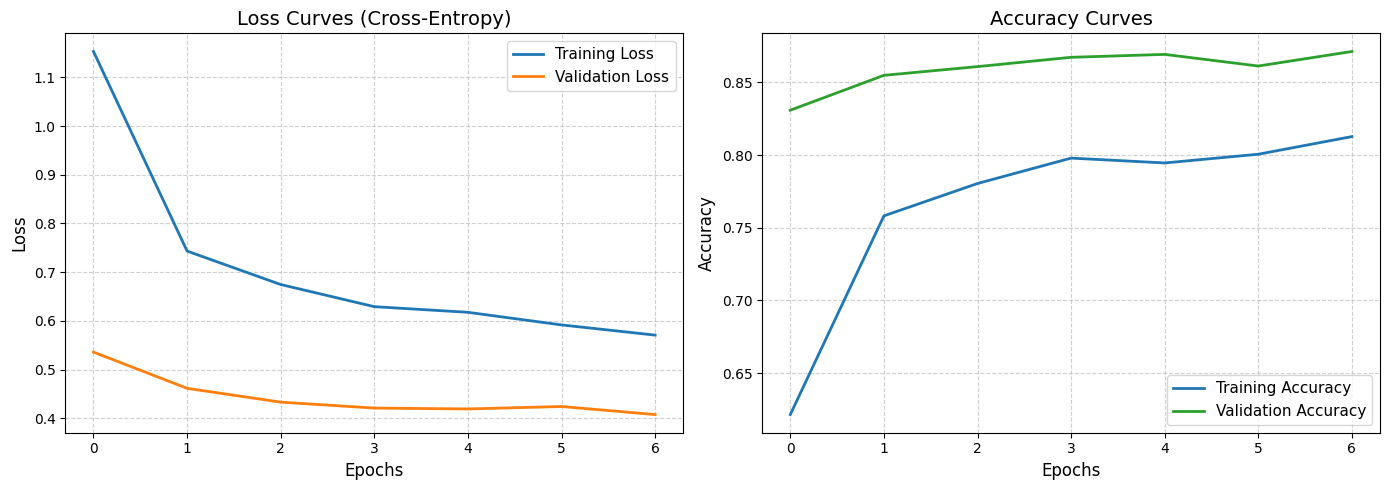

In [14]:
import matplotlib.pyplot as plt

def plot_loss_curves(history):
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]

    epochs = range(len(history.history["loss"]))

    # Setup 1x2 plot grid
    plt.figure(figsize=(14, 5))

    # 1. Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label="Training Loss", color="#1f77b4", linewidth=2)
    plt.plot(epochs, val_loss, label="Validation Loss", color="#ff7f0e", linewidth=2)
    plt.title("Loss Curves (Cross-Entropy)", fontsize=14)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel("Loss", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=11)

    # 2. Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label="Training Accuracy", color="#1f77b4", linewidth=2)
    plt.plot(epochs, val_accuracy, label="Validation Accuracy", color="#2ca02c", linewidth=2)
    plt.title("Accuracy Curves", fontsize=14)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel("Accuracy", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=11)

    plt.tight_layout()
    plt.savefig("nutriscore_training_curves.png", dpi=300)
    plt.show()

# Execute plot
plot_loss_curves(history)

## 8. Detailed Evaluation Metrics & Confusion Matrix

We evaluate fine-grained performance on the unseen test set:
- Precision, Recall, and F1-Score across all 10 categories
- Multi-Class Confusion Matrix to visualize inter-class confusion patterns

Generating predictions on the test set...
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 137ms/step

CLASSIFICATION REPORT
                precision    recall  f1-score   support

 chicken_curry       0.81      0.78      0.80       250
 chicken_wings       0.82      0.90      0.86       250
    fried_rice       0.91      0.90      0.90       250
grilled_salmon       0.73      0.80      0.76       250
     hamburger       0.90      0.92      0.91       250
     ice_cream       0.95      0.92      0.93       250
         pizza       0.94      0.98      0.96       250
         ramen       0.91      0.89      0.90       250
         steak       0.88      0.73      0.79       250
         sushi       0.90      0.89      0.90       250

      accuracy                           0.87      2500
     macro avg       0.87      0.87      0.87      2500
  weighted avg       0.87      0.87      0.87      2500



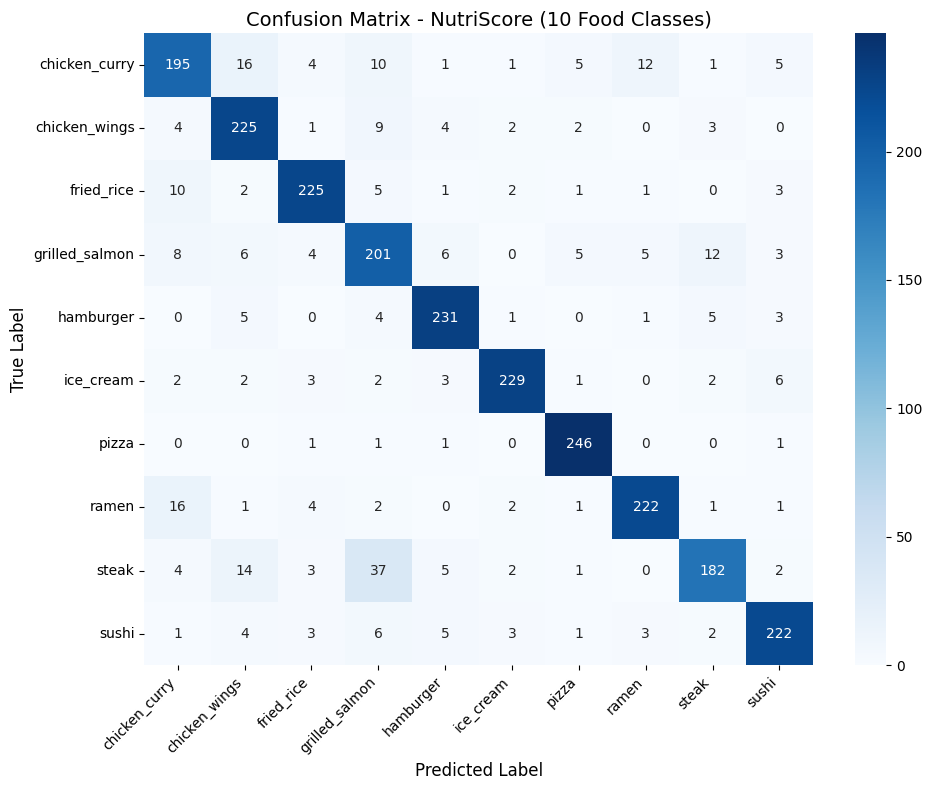

In [15]:
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Generating predictions on the test set...")

# 1. Get predicted probabilities on test data
y_pred_probs = model.predict(test_data)

# 2. Convert probabilities to predicted class indices (argmax)
y_pred_labels = np.argmax(y_pred_probs, axis=1)

# 3. Extract the true labels from test_data
y_true_labels = []
for images, labels in test_data:
    # labels are one-hot encoded, so argmax gives the true class index
    y_true_labels.extend(np.argmax(labels.numpy(), axis=1))

y_true_labels = np.array(y_true_labels)

# 4. Print Classification Report (Precision, Recall, F1)
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true_labels, y_pred_labels, target_names=class_names))

# 5. Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_true_labels, y_pred_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("Confusion Matrix - NutriScore (10 Food Classes)", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("nutriscore_confusion_matrix.png", dpi=300)
plt.show()

## 9. End-to-End Prediction & Nutri-Score Nutritional Analysis Engine

We integrate the trained classifier with the nutrition database to:
1. Classify an unseen food image and output the confidence score.
2. Lookup macronutrient values (Calories, Protein, Carbs, Fats).
3. Assign the official European Nutri-Score grade (A to E).
4. Provide actionable health recommendations.

In [16]:
import pandas as pd
from tensorflow.keras.preprocessing import image

# 1. Define Nutrition & Nutri-Score Database for our 10 classes
nutrition_data = {
    "chicken_curry": {
        "display_name": "Chicken Curry",
        "serving": "1 bowl (250g)",
        "calories": 320,
        "protein": 24.0,
        "carbs": 12.0,
        "fat": 18.0,
        "fiber": 2.5,
        "nutriscore": "B",
        "health_note": "Rich source of lean protein. Moderate saturated fats; pair with brown rice or roti."
    },
    "chicken_wings": {
        "display_name": "Chicken Wings (Fried)",
        "serving": "4 pieces (180g)",
        "calories": 430,
        "protein": 30.0,
        "carbs": 14.0,
        "fat": 28.0,
        "fiber": 0.5,
        "nutriscore": "D",
        "health_note": "High in protein but elevated in sodium and saturated fats from frying. Consume in moderation."
    },
    "fried_rice": {
        "display_name": "Fried Rice",
        "serving": "1 bowl (200g)",
        "calories": 330,
        "protein": 7.5,
        "carbs": 54.0,
        "fat": 9.5,
        "fiber": 2.0,
        "nutriscore": "C",
        "health_note": "High glycemic carbohydrate meal. Add extra vegetables and eggs to improve nutrient density."
    },
    "grilled_salmon": {
        "display_name": "Grilled Salmon",
        "serving": "1 fillet (180g)",
        "calories": 340,
        "protein": 34.0,
        "carbs": 0.0,
        "fat": 20.0,
        "fiber": 0.0,
        "nutriscore": "A",
        "health_note": "Exceptional heart-healthy meal rich in complete protein and essential Omega-3 fatty acids."
    },
    "hamburger": {
        "display_name": "Hamburger / Cheeseburger",
        "serving": "1 sandwich (220g)",
        "calories": 540,
        "protein": 28.0,
        "carbs": 40.0,
        "fat": 30.0,
        "fiber": 3.0,
        "nutriscore": "D",
        "health_note": "High energy density and saturated fat content. Recommend limiting extra mayo and melted cheese."
    },
    "ice_cream": {
        "display_name": "Ice Cream",
        "serving": "1 cup (132g)",
        "calories": 273,
        "protein": 4.6,
        "carbs": 31.6,
        "fat": 14.5,
        "fiber": 0.9,
        "nutriscore": "E",
        "health_note": "High in refined sugars and dairy fats. Best enjoyed as an occasional treat in small portions."
    },
    "pizza": {
        "display_name": "Pizza (Cheese/Pepperoni)",
        "serving": "1 slice (107g)",
        "calories": 266,
        "protein": 11.0,
        "carbs": 33.0,
        "fat": 10.0,
        "fiber": 2.3,
        "nutriscore": "D",
        "health_note": "High refined carbohydrates and sodium. Balance with a fresh green salad."
    },
    "ramen": {
        "display_name": "Ramen Noodle Soup",
        "serving": "1 bowl (400g)",
        "calories": 430,
        "protein": 14.0,
        "carbs": 55.0,
        "fat": 16.0,
        "fiber": 3.2,
        "nutriscore": "C",
        "health_note": "Comfort meal with good carbs. Watch the broth intake if monitoring dietary sodium."
    },
    "steak": {
        "display_name": "Grilled Steak",
        "serving": "1 steak (200g)",
        "calories": 450,
        "protein": 48.0,
        "carbs": 0.0,
        "fat": 28.0,
        "fiber": 0.0,
        "nutriscore": "B",
        "health_note": "High-quality complete protein and bioavailable iron. Moderate portion sizes for saturated fat control."
    },
    "sushi": {
        "display_name": "Sushi (Assorted Rolls)",
        "serving": "6 pieces (200g)",
        "calories": 250,
        "protein": 9.0,
        "carbs": 38.0,
        "fat": 5.0,
        "fiber": 2.8,
        "nutriscore": "B",
        "health_note": "Lean, low-fat nutrient source. Mindful of dipping soy sauce for sodium moderation."
    }
}

# 2. Nutri-Score Color Mapping
nutriscore_badge = {
    "A": "🟩 Grade A (Nutritional Quality: Excellent)",
    "B": "🟢 Grade B (Nutritional Quality: Good)",
    "C": "🟡 Grade C (Nutritional Quality: Moderate / Balanced)",
    "D": "🟧 Grade D (Nutritional Quality: Poor / Moderate Consumption)",
    "E": "🟥 Grade E (Nutritional Quality: Unfavorable / High Fat & Sugar)"
}

# 3. Prediction & Analysis Function
def predict_and_analyze_food(img_path):
    # Load and preprocess image
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)  # Shape: (1, 224, 224, 3)

    # Predict using the model
    preds = model.predict(img_batch, verbose=0)[0]
    pred_index = np.argmax(preds)
    pred_class = class_names[pred_index]
    confidence = preds[pred_index] * 100

    # Retrieve Nutrition Data
    nutri = nutrition_data.get(pred_class, None)

    # Display image and report
    plt.figure(figsize=(6, 6))
    plt.imshow(image.load_img(img_path))
    plt.title(f"Predicted: {nutri['display_name']} ({confidence:.1f}%)", fontsize=14, weight="bold")
    plt.axis("off")
    plt.show()

    print("=" * 65)
    print(f"🍽️  FOOD ITEM: {nutri['display_name']} (Confidence: {confidence:.2f}%)")
    print(f"🏷️  NUTRI-SCORE: {nutriscore_badge[nutri['nutriscore']]}")
    print("-" * 65)
    print(f"📦 Serving Size : {nutri['serving']}")
    print(f"🔥 Calories     : {nutri['calories']} kcal")
    print(f"🥩 Protein      : {nutri['protein']} g")
    print(f"🍞 Carbohydrates: {nutri['carbs']} g")
    print(f"🥑 Total Fat    : {nutri['fat']} g")
    print(f"🌾 Fiber        : {nutri['fiber']} g")
    print("-" * 65)
    print(f"💡 Health Recommendation:\n   {nutri['health_note']}")
    print("=" * 65)

Testing on an unseen image from: ice_cream


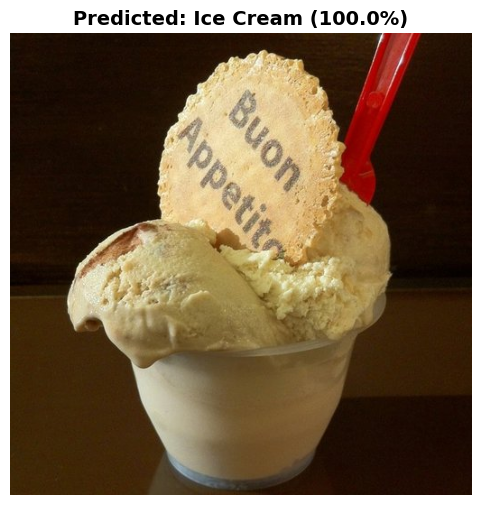

🍽️  FOOD ITEM: Ice Cream (Confidence: 100.00%)
🏷️  NUTRI-SCORE: 🟥 Grade E (Nutritional Quality: Unfavorable / High Fat & Sugar)
-----------------------------------------------------------------
📦 Serving Size : 1 cup (132g)
🔥 Calories     : 273 kcal
🥩 Protein      : 4.6 g
🍞 Carbohydrates: 31.6 g
🥑 Total Fat    : 14.5 g
🌾 Fiber        : 0.9 g
-----------------------------------------------------------------
💡 Health Recommendation:
   High in refined sugars and dairy fats. Best enjoyed as an occasional treat in small portions.


In [17]:
import random

# Pick a random class and a random test image
sample_class = random.choice(class_names)
sample_dir = os.path.join(test_dir, sample_class)
sample_img = random.choice(os.listdir(sample_dir))
sample_img_path = os.path.join(sample_dir, sample_img)

print(f"Testing on an unseen image from: {sample_class}")
predict_and_analyze_food(sample_img_path)